In [1]:
import torch
from torch import nn
import numpy as np

In [2]:
from pathlib import Path
data_path=Path("data/")
image_path=data_path /"desert101"

In [3]:
image_path

WindowsPath('data/desert101')

In [4]:
import os

In [5]:
def check_data(dir_path):
    for dirpath,dirnames,filenames in os.walk(dir_path):
        print(f"# of directories : {len(dirnames)} and {len(filenames)} images in {dirpath}")

In [6]:
check_data(image_path)

# of directories : 2 and 1 images in data\desert101
# of directories : 4 and 1 images in data\desert101\test
# of directories : 0 and 20 images in data\desert101\test\baklava
# of directories : 0 and 20 images in data\desert101\test\cannoli
# of directories : 0 and 20 images in data\desert101\test\cup_cakes
# of directories : 0 and 20 images in data\desert101\test\donuts
# of directories : 4 and 1 images in data\desert101\train
# of directories : 0 and 80 images in data\desert101\train\baklava
# of directories : 0 and 80 images in data\desert101\train\cannoli
# of directories : 0 and 80 images in data\desert101\train\cup_cakes
# of directories : 0 and 80 images in data\desert101\train\donuts


In [7]:
train_dir=image_path / "train"
test_dir=image_path / "test"

In [8]:
train_dir

WindowsPath('data/desert101/train')

In [9]:
test_dir

WindowsPath('data/desert101/test')

In [10]:
from PIL import Image
import random

In [11]:
random.seed(42)

image_path_list=list(image_path.glob('*/*/*.jpg'))
random_image=random.choice(image_path_list)
img= Image.open(random_image)

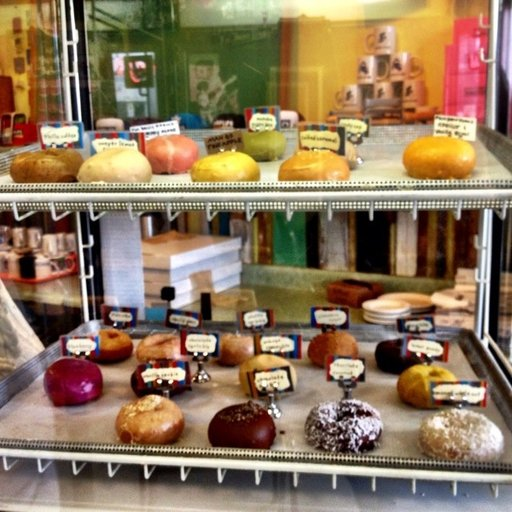

In [12]:
img

In [13]:
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

In [14]:

stats_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

stats_dataset = datasets.ImageFolder(
    root=train_dir,
    transform=stats_transform
)

stats_loader = DataLoader(
    stats_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)


channel_sum = torch.zeros(3)
channel_sum_sq = torch.zeros(3)
pixel_count = 0

for images, labels in stats_loader:
    channel_sum += images.sum(dim=(0, 2, 3))
    channel_sum_sq += (images ** 2).sum(dim=(0, 2, 3))
    pixel_count += images.shape[0] * images.shape[2] * images.shape[3]

mean = channel_sum / pixel_count
std = torch.sqrt(channel_sum_sq / pixel_count - mean ** 2)


print("Mean:", mean.tolist())
print("Std:", std.tolist())

Mean: [0.5482884049415588, 0.46379244327545166, 0.38653966784477234]
Std: [0.2541806399822235, 0.25764989852905273, 0.26304277777671814]


In [15]:
mean=mean.tolist()

In [16]:
std=std.tolist()

In [17]:
mean

[0.5482884049415588, 0.46379244327545166, 0.38653966784477234]

In [18]:
std

[0.2541806399822235, 0.25764989852905273, 0.26304277777671814]

In [19]:
class AddGaussşanNoise:
    def __init__(self,mean=0.,std=0.05):
        self.mean=mean
        self.std=std
    def __call__(self,tensor):
        noise=torch.randn_like(tensor)*self.std +self.mean
        return tensor + noise

In [20]:
data_transform = transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.TrivialAugmentWide(),
    transforms.ToTensor(),
    AddGaussşanNoise(mean=0.,std=0.05),
    transforms.Normalize(mean,std)
])

In [21]:
data_test_transform=transforms.Compose([
    transforms.Resize(size=(64,64)),
    transforms.ToTensor(),
    transforms.Normalize(mean,std)
])

In [22]:
train_data=datasets.ImageFolder(root=train_dir,
                     transform=data_transform,
                    target_transform=None)
test_data=datasets.ImageFolder(root=test_dir,
                     transform=data_test_transform)


In [23]:
train_data

Dataset ImageFolder
    Number of datapoints: 316
    Root location: data\desert101\train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
               TrivialAugmentWide(num_magnitude_bins=31, interpolation=InterpolationMode.NEAREST, fill=None)
               ToTensor()
               Normalize(mean=[0.5482884049415588, 0.46379244327545166, 0.38653966784477234], std=[0.2541806399822235, 0.25764989852905273, 0.26304277777671814])
           )

In [24]:
test_data

Dataset ImageFolder
    Number of datapoints: 77
    Root location: data\desert101\test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
               Normalize(mean=[0.5482884049415588, 0.46379244327545166, 0.38653966784477234], std=[0.2541806399822235, 0.25764989852905273, 0.26304277777671814])
           )

In [25]:
class_names=train_data.classes

In [26]:
class_names

['baklava', 'cannoli', 'cup_cakes', 'donuts']

In [27]:
len(train_data),len(test_data)

(316, 77)

In [28]:
BATCH_SIZE=32
NUM_WORKERS=0

In [29]:
train_dataloader=DataLoader(dataset=train_data,
                            batch_size=BATCH_SIZE,
                            num_workers=NUM_WORKERS,
                            shuffle=True)
test_dataloader=DataLoader(dataset=test_data,
                            batch_size=BATCH_SIZE,
                            num_workers=NUM_WORKERS,
                            shuffle=False)

In [30]:
train_dataloader.dataset[0][0]

tensor([[[-1.9386, -2.1738, -2.1128,  ..., -2.3217, -1.8787, -2.1738],
         [-2.1552, -2.2113, -2.1337,  ..., -2.0878, -2.0115, -1.8750],
         [-2.1013, -1.8694, -2.1693,  ..., -2.0857, -2.2294, -2.1109],
         ...,
         [-2.5212, -1.9791, -2.3069,  ..., -2.2451, -2.1247, -2.1881],
         [-2.0333, -2.1866, -1.9767,  ..., -1.8467, -2.0370, -1.9638],
         [-2.4146, -2.2154, -2.0523,  ..., -2.1337, -1.9860, -2.1755]],

        [[-1.6198, -1.7501, -1.3817,  ..., -1.9142, -1.3581, -1.6458],
         [-1.8620, -2.0070, -1.8545,  ..., -2.0160, -1.6173, -1.8308],
         [-1.7010, -1.4404, -1.7126,  ..., -1.7415, -1.5712, -1.9197],
         ...,
         [-1.9025, -1.8255, -1.5845,  ..., -1.6768, -1.8576, -1.8061],
         [-1.9486, -1.9309, -1.7544,  ..., -2.0012, -1.8186, -2.0501],
         [-1.5023, -1.7275, -1.8515,  ..., -1.8798, -1.9621, -1.6454]],

        [[-1.2386, -1.6452, -1.5974,  ..., -1.3023, -1.5786, -1.8491],
         [-1.5401, -1.2605, -1.5455,  ..., -1

In [31]:
class DesertClassifier(nn.Module):
    def __init__(self,input_shape:int,hidden_units:int,output_shape:int):
        super().__init__()

        self.conv_block1=nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )
        self.conv_block2=nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                     stride=1,
                     padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                     out_channels=hidden_units,
                     kernel_size=3,
                      stride=1,
                      padding=1
                     ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2)
        )
        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units*16*16,
                     out_features=output_shape
                     )
            )
    def forward(self,x):
        return self.classifier(self.conv_block2(self.conv_block1(x)))

In [32]:
model0=DesertClassifier(input_shape=3,hidden_units=32,output_shape=len(class_names))

In [33]:
!pip install torchinfo

In [34]:
from torchinfo import summary

In [35]:
summary(model=model0,input_size=[1,3,64,64])

Layer (type:depth-idx)                   Output Shape              Param #
DesertClassifier                         [1, 4]                    --
├─Sequential: 1-1                        [1, 32, 32, 32]           --
│    └─Conv2d: 2-1                       [1, 32, 64, 64]           896
│    └─ReLU: 2-2                         [1, 32, 64, 64]           --
│    └─Conv2d: 2-3                       [1, 32, 64, 64]           9,248
│    └─ReLU: 2-4                         [1, 32, 64, 64]           --
│    └─MaxPool2d: 2-5                    [1, 32, 32, 32]           --
├─Sequential: 1-2                        [1, 32, 16, 16]           --
│    └─Conv2d: 2-6                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-7                         [1, 32, 32, 32]           --
│    └─Conv2d: 2-8                       [1, 32, 32, 32]           9,248
│    └─ReLU: 2-9                         [1, 32, 32, 32]           --
│    └─MaxPool2d: 2-10                   [1, 32, 16, 16]           --
├─Seq

In [36]:
def train_step(model:torch.nn.Module,dataloader:torch.utils.DataLoader,
              loss_fn:torch.nn.Module,optimizer:torch.optim.Optimizer):

    model.train()

    train_loss=0
    train_acc=0

    for batch,(X,y) in enumerate(dataloader):

        y_pred=model(X)
        loss=loss_fn(y_pred,y)
        train_loss +=loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        y_pred_class= torch.argmax(torch.softmax(y_pred,dim=1),dim=1)
        train_acc +=(y_pred_class==y).sum().item() / len(y_pred)

    train_loss=train_loss / len(dataloader)
    train_acc=train_acc/ len(dataloader)
    return train_loss,train_acc        

In [37]:
def test_step(model:torch.nn.Module,dataloader:torch.utils.DataLoader,
             loss_fn:torch.nn.Module):
    model.eval()
    
    test_loss=0
    test_acc=0
    
    with torch.inference_mode():
        for batch,(X,y) in enumerate(dataloader):
            test_pred_logits=model(X)
            loss=loss_fn(test_pred_logits,y)
            test_loss +=loss.item()

            test_pred_labels=test_pred_logits.argmax(dim=1)
            test_acc +=(test_pred_labels==y).sum().item() / len(test_pred_labels)

    test_loss =test_loss /len(dataloader)
    test_acc=test_acc / len(dataloader)
    return test_loss,test_acc

In [38]:
def train(model:torch.nn.Module,
          train_dataloader:torch.utils.DataLoader,
          test_dataloader:torch.utils.DataLoader,
          optimizer:torch.optim.Optimizer,
            loss_fn:torch.nn.Module =nn.CrossEntropyLoss(),
         epochs: int=10):
    results= {"train_loss":[],
             "train_acc":[],
              "test_loss":[],
              "test_acc":[]
             }
    for epoch in range (epochs):
        train_loss,train_acc=train_step(model=model,
                                       dataloader=train_dataloader,
                                       loss_fn=loss_fn,
                                        optimizer=optimizer)
        test_loss,test_acc=test_step(model=model,
                                    dataloader=test_dataloader,
                                    loss_fn=loss_fn)
        print(f"Epoch:{epoch},Train Loss:{train_loss},Train Acc:{train_acc},Test Loss:{test_loss},Test Acc:{test_acc}")

        results["train_loss"].append(train_loss.item() if isinstance(train_loss,torch.Tensor)else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc,torch.Tensor)else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss,torch.Tensor)else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc,torch.Tensor)else test_acc)
    return results

In [39]:
EPOCHS =10
model_0=DesertClassifier(input_shape=3,
                        hidden_units=32,
                       output_shape=len(class_names))
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(params=model_0.parameters(),lr=0.001)

model_0_results =train(model=model_0,
                      train_dataloader=train_dataloader,
                      test_dataloader=test_dataloader,
                      optimizer=optimizer,
                      loss_fn=loss_fn,
                      epochs=EPOCHS)

Epoch:0,Train Loss:1.3996295213699341,Train Acc:0.22142857142857145,Test Loss:1.3890350262324016,Test Acc:0.20833333333333334
Epoch:1,Train Loss:1.3844334483146667,Train Acc:0.25357142857142856,Test Loss:1.3894826968510945,Test Acc:0.32211538461538464
Epoch:2,Train Loss:1.3521645426750184,Train Acc:0.3522321428571428,Test Loss:1.3766669034957886,Test Acc:0.3838141025641026
Epoch:3,Train Loss:1.342185640335083,Train Acc:0.3625,Test Loss:1.3431615034739177,Test Acc:0.327724358974359
Epoch:4,Train Loss:1.303495192527771,Train Acc:0.36919642857142854,Test Loss:1.282409429550171,Test Acc:0.36378205128205127
Epoch:5,Train Loss:1.271641230583191,Train Acc:0.40223214285714287,Test Loss:1.3363018830617268,Test Acc:0.3846153846153846
Epoch:6,Train Loss:1.2976701855659485,Train Acc:0.41294642857142855,Test Loss:1.227071483929952,Test Acc:0.4615384615384615
Epoch:7,Train Loss:1.2525608897209168,Train Acc:0.41205357142857146,Test Loss:1.281473159790039,Test Acc:0.358974358974359
Epoch:8,Train Loss:

In [40]:
model_0_results

{'train_loss': [1.3996295213699341,
  1.3844334483146667,
  1.3521645426750184,
  1.342185640335083,
  1.303495192527771,
  1.271641230583191,
  1.2976701855659485,
  1.2525608897209168,
  1.2413618564605713,
  1.2729210138320923],
 'train_acc': [0.22142857142857145,
  0.25357142857142856,
  0.3522321428571428,
  0.3625,
  0.36919642857142854,
  0.40223214285714287,
  0.41294642857142855,
  0.41205357142857146,
  0.43660714285714286,
  0.4241071428571429],
 'test_loss': [1.3890350262324016,
  1.3894826968510945,
  1.3766669034957886,
  1.3431615034739177,
  1.282409429550171,
  1.3363018830617268,
  1.227071483929952,
  1.281473159790039,
  1.3176409602165222,
  1.1915191411972046],
 'test_acc': [0.20833333333333334,
  0.32211538461538464,
  0.3838141025641026,
  0.327724358974359,
  0.36378205128205127,
  0.3846153846153846,
  0.4615384615384615,
  0.358974358974359,
  0.3125,
  0.5440705128205128]}

In [41]:
import matplotlib.pyplot as plt

In [42]:
def plot_loss_curves(results):
    loss=results["train_loss"]
    test_loss=results["test_loss"]
    accuarcy=results["train_acc"]
    test_accuary=results["test_acc"]

    epochs= range(len(results["train_loss"]))

    plt.figure(figsize=(16,8))

    plt.subplot(1,2,1)
    plt.plot(epochs,loss,label="train_loss")
    plt.plot(epochs,test_loss,label="test_loss")
    plt.title("Loss")
    plt.xlabel("Epochs")
    plt.legend()
    
    plt.subplot(1,2,2)
    plt.plot(epochs,accuarcy,label="train_accuracy")
    plt.plot(epochs,test_accuary,label="test_accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epochs")
    plt.legend()

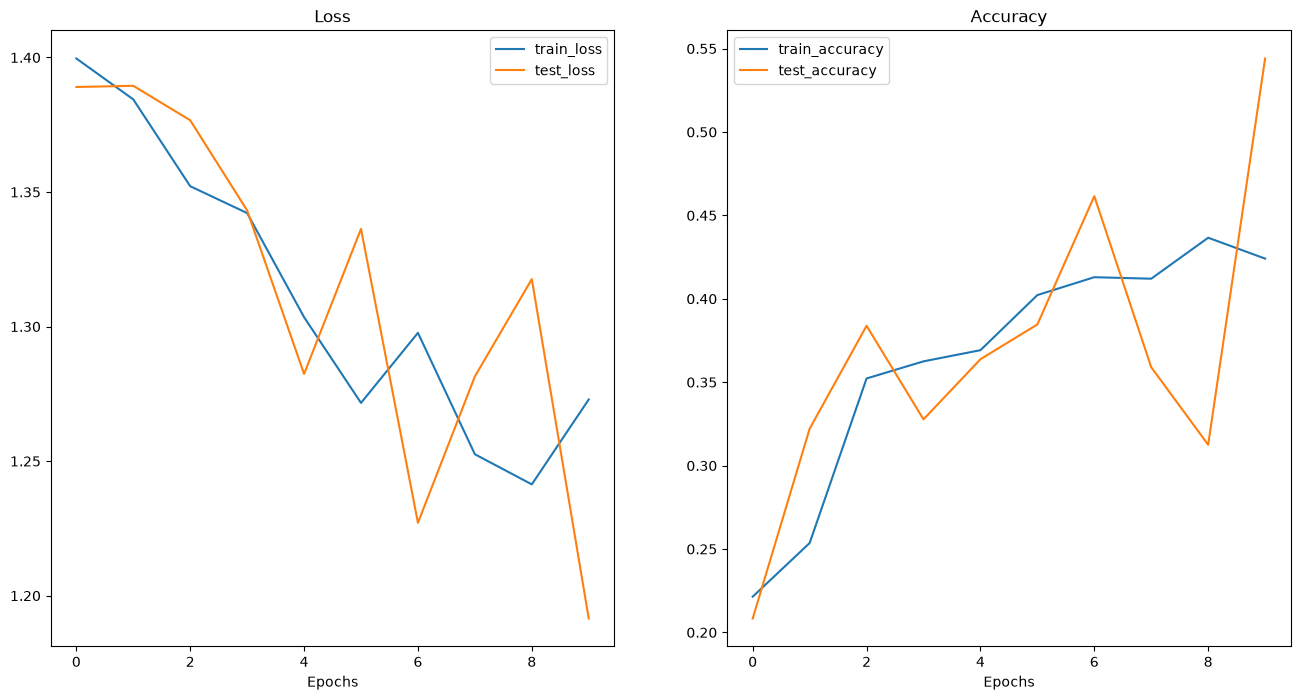

In [43]:
plot_loss_curves(model_0_results)

In [44]:
def make_predictions(model: torch.nn.Module, data: list):
    """
    data: [img_tensor, img_tensor, ...]  # her biri [C, H, W]
    return: [N, num_classes] olasılık tensörü
    """
    pred_probs = []
    model.eval()

    with torch.inference_mode():
        for sample in data:
            # [C, H, W] -> [1, C, H, W]
            sample = sample.unsqueeze(0)

            # Logits al
            pred_logit = model(sample)    # shape: [1, num_classes]

            # Softmax ile olasılığa çevir
            prob = torch.softmax(pred_logit, dim=1)  # [1, num_classes]

            # Batch boyutunu sıkıştır
            pred_probs.append(prob.squeeze(0))       # [num_classes]

    # Hepsini birleştir → [N, num_classes]
    return torch.stack(pred_probs)

In [45]:
import random
def show_random_predictions(model, dataset, class_names, n=9):
    model.eval()
    
    plt.figure(figsize=(4, 4))

    # random 9 index seç
    indices = random.sample(range(len(dataset)), n)

    with torch.inference_mode():
        for i, idx in enumerate(indices):
            img, true_label = dataset[idx]

            # modele uygun hale getir
            img_input = img.unsqueeze(0)  
            logits = model(img_input)
            pred_label = logits.argmax(dim=1).item()

            # görseli çizmek için permute
            img_show = img.permute(1, 2, 0)

            # doğru mu yanlış mı?
            correct = (pred_label == true_label)
            color = "green" if correct else "red"

            # subplot
            plt.subplot(3, 3, i + 1)
            plt.imshow(img_show)
            plt.axis("off")

            plt.title(
                f"Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}",
                color=color,
                fontsize=10
            )

    plt.tight_layout()
    plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7868031..2.3321693].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.110797..1.855098].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.064512..1.8700066].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0182273..1.3780266].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1416535..2.3023524].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.2756833..2.3321693].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5413388..

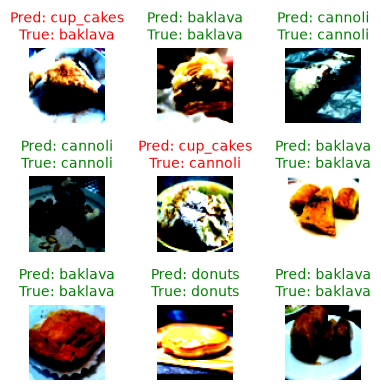

In [46]:
show_random_predictions(model_0,test_data,class_names)

In [47]:
online_image_path=data_path/"baklava-online.jpg"

In [48]:
online_image_path

WindowsPath('data/baklava-online.jpg')

In [49]:
import torchvision

In [50]:
single_image=torchvision.io.read_image(str(online_image_path)).type(torch.float32)

In [51]:
single_image=single_image/255

In [52]:
single_image

tensor([[[0.8392, 0.8392, 0.8392,  ..., 0.8627, 0.8431, 0.8431],
         [0.8392, 0.8392, 0.8392,  ..., 0.8627, 0.8471, 0.8471],
         [0.8392, 0.8392, 0.8392,  ..., 0.8627, 0.8471, 0.8471],
         ...,
         [0.8039, 0.8235, 0.8667,  ..., 0.8392, 0.8431, 0.8431],
         [0.8078, 0.8471, 0.8941,  ..., 0.8902, 0.8471, 0.7804],
         [0.8078, 0.8471, 0.8941,  ..., 0.8902, 0.8471, 0.7804]],

        [[0.8039, 0.8039, 0.8039,  ..., 0.8039, 0.7843, 0.7843],
         [0.8039, 0.8039, 0.8039,  ..., 0.8039, 0.7882, 0.7882],
         [0.8039, 0.8039, 0.8039,  ..., 0.8039, 0.7882, 0.7882],
         ...,
         [0.7843, 0.8039, 0.8471,  ..., 0.7961, 0.7882, 0.7882],
         [0.7882, 0.8275, 0.8745,  ..., 0.8471, 0.7922, 0.7255],
         [0.7882, 0.8275, 0.8745,  ..., 0.8471, 0.7922, 0.7255]],

        [[0.7765, 0.7765, 0.7765,  ..., 0.7765, 0.7569, 0.7569],
         [0.7765, 0.7765, 0.7765,  ..., 0.7765, 0.7608, 0.7608],
         [0.7765, 0.7765, 0.7765,  ..., 0.7765, 0.7608, 0.

Text(0.5, 1.0, 'torch.Size([3, 554, 554])')

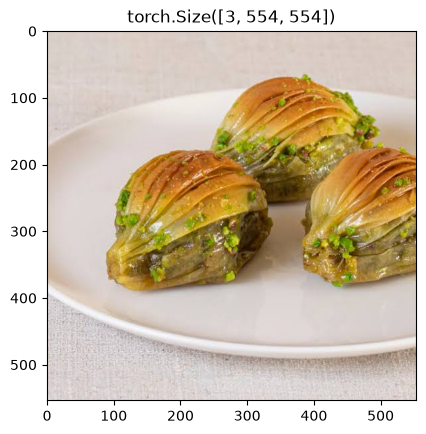

In [53]:
plt.imshow(single_image.permute(1,2,0))
plt.title(single_image.shape)

In [54]:
single_image_transform=transforms.Compose(
    [
        transforms.Resize(size=(64,64))
    ]
)

single_image=single_image_transform(single_image)

In [55]:
single_image.shape

torch.Size([3, 64, 64])

In [56]:
single_image.unsqueeze(dim=0).shape

torch.Size([1, 3, 64, 64])

In [57]:
single_image=single_image.unsqueeze(dim=0)

In [58]:
single_image

tensor([[[[0.8454, 0.8505, 0.8509,  ..., 0.8540, 0.8528, 0.8573],
          [0.8467, 0.8457, 0.8478,  ..., 0.8569, 0.8532, 0.8549],
          [0.8471, 0.8503, 0.8502,  ..., 0.8546, 0.8486, 0.8478],
          ...,
          [0.8571, 0.8575, 0.8532,  ..., 0.8536, 0.8604, 0.8517],
          [0.8556, 0.8571, 0.8511,  ..., 0.8678, 0.8626, 0.8614],
          [0.8542, 0.8576, 0.8524,  ..., 0.8563, 0.8542, 0.8572]],

         [[0.8102, 0.8136, 0.8083,  ..., 0.7952, 0.7940, 0.7985],
          [0.8114, 0.8090, 0.8067,  ..., 0.7981, 0.7943, 0.7961],
          [0.8118, 0.8149, 0.8144,  ..., 0.7958, 0.7898, 0.7890],
          ...,
          [0.8179, 0.8198, 0.8209,  ..., 0.8157, 0.8235, 0.8123],
          [0.8203, 0.8233, 0.8188,  ..., 0.8312, 0.8288, 0.8296],
          [0.8324, 0.8343, 0.8221,  ..., 0.8234, 0.8212, 0.8164]],

         [[0.7827, 0.7869, 0.7845,  ..., 0.7677, 0.7666, 0.7710],
          [0.7839, 0.7823, 0.7821,  ..., 0.7706, 0.7669, 0.7686],
          [0.7843, 0.7875, 0.7872,  ..., 0

In [59]:
model_0.eval()
with torch.inference_mode():
    logits=model_0(single_image)
    probs=torch.softmax(logits,dim=1)
    pred_idx=probs.argmax(dim=1).item()
print("Predic class:",class_names[pred_idx])

Predic class: cannoli
